# Две башни: данные, критерий обучения и диагностика

Проверяем, как история и условия обучения влияют на две башни. На 1286–1292 правильная история помогла модели, но личная частота дала больший Recall.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/03_two_tower'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Запуск этапа

`saved` показывает результаты прежних опытов. Для `train` задайте каталог данных и выполняйте главы по порядку.

In [2]:
# В saved обучение не вызывается. В train выполняется соответствующий этап.
session.run("03_two_tower")
result_table = session.metrics("03_two_tower")
if MODE == 'train':
    display(result_table)

Используем сохранённые результаты.


## Результаты экспериментов

## Архитектура и входы

Товарная башня объединяет ID и вектор товара. Пользовательская обрабатывает взвешенную историю с остаточной связью. Ниже — параметры запуска для оценки на 1286–1292.

In [3]:
config = json.loads((root / 'configs/stable_two_tower.json').read_text())
keys = ['seed','pairs','training_users','positive_items','batch_size','maximum_epochs','lr','temperature','negative_draws']
display(pd.Series({key: config[key] for key in keys}, name='Контроль на неделе1286'))

seed                2026.0000
pairs             383441.0000
training_users     79689.0000
positive_items     58450.0000
batch_size           512.0000
maximum_epochs         8.0000
lr                     0.0003
temperature            0.1000
negative_draws       256.0000
Name: Контроль на неделе1286, dtype: float64

## Негативные примеры и функция потерь

Показаны выбор негативов, поправка на вероятность их выбора и Cosine Contrastive Loss. Полные циклы обучения находятся в `engine/`.

In [4]:
def draw_negative_candidates(ids, q, cdf, positive, known_positives, rng, draws=256):
    assert np.isclose(q.sum(),1) and (q > 0).all()
    locations = np.searchsorted(cdf, rng.random((len(positive),draws)))
    negative = ids[locations]
    excluded = np.stack([np.isin(row, forbidden) for row,forbidden in zip(negative,known_positives)])
    candidates = np.column_stack([positive,negative])+1  # zero reserves padding
    return candidates, q[locations], excluded

def importance_loss(cosine, q_negative, excluded, temperature=.1):
    import torch
    score = cosine / temperature
    draws = q_negative.shape[1]
    negative = (score[:,1:] - torch.log(draws*q_negative)).masked_fill(excluded,-torch.inf)
    return torch.logsumexp(torch.cat([score[:,:1],negative],dim=1),dim=1)-score[:,0]

def cosine_contrastive_loss(cosine, excluded, margin=.5, negative_weight=50.):
    valid = ~excluded
    negative = ((cosine[:,1:]-margin).clamp_min(0)*valid).sum(1)/valid.sum(1).clamp_min(1)
    return 1-cosine[:,0]+negative_weight*negative

## Четыре и восемь недель обучения

Максимальный бюджет одинаков: 4000 обновлений. Число обучающих пар и проходов различается.

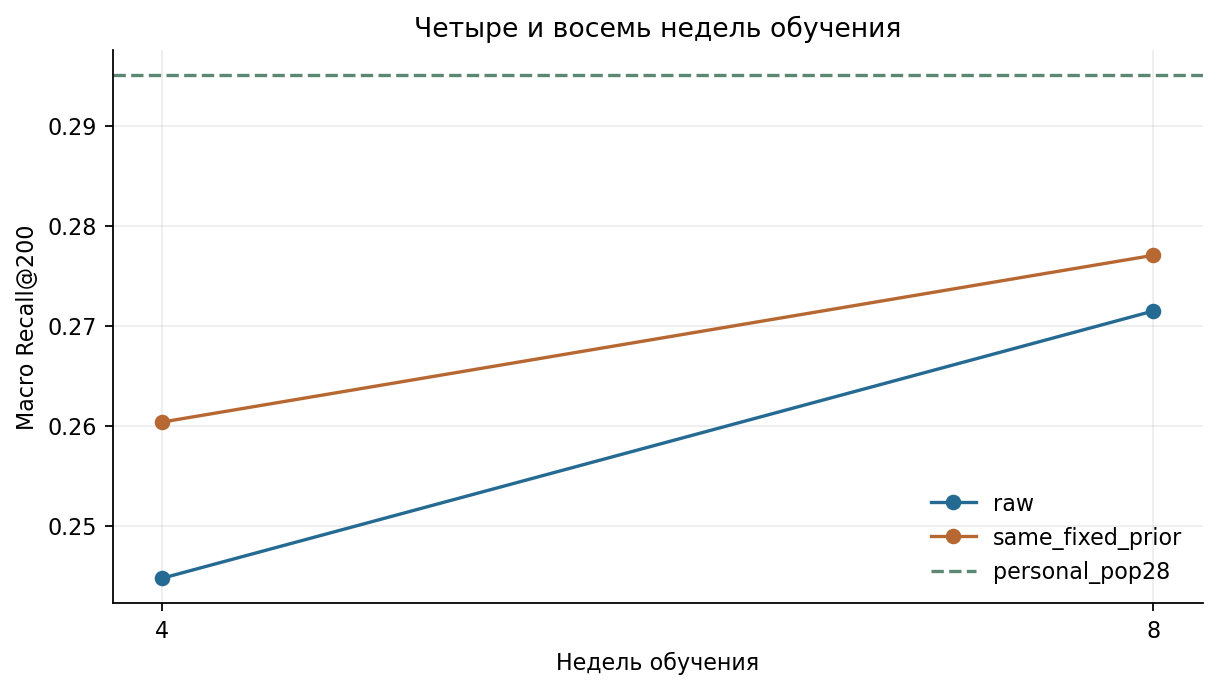

,weeks,scoring,training_pairs,best_updates,recall_reachable@200,own_minus_shuffled
0,4,raw,119328,1000,0.244758,0.009197
1,4,same_fixed_prior,119328,1000,0.260367,0.006156
2,8,raw,307359,3000,0.271460,0.013332
3,8,same_fixed_prior,307359,3000,0.277029,0.009519


In [5]:
weeks = read('full_catalog_20261104__comparison.csv')
fig, ax = plt.subplots(figsize=(7.5,4.2))
for scoring,color in [('raw','#246A92'),('same_fixed_prior','#B76832')]:
    d = weeks[weeks.scoring == scoring].sort_values('weeks')
    ax.plot(d.weeks,d['recall_reachable@200'],'o-',label=scoring,color=color)
ax.axhline(.2950456062720093,color='#5C8873',linestyle='--',label='personal_pop28')
ax.set(xticks=[4,8],xlabel='Недель обучения',ylabel='Macro Recall@200',title='Четыре и восемь недель обучения')
ax.legend(frameon=False)
save_figure(fig, figures / 'train_weeks.png')
plt.show()
display(weeks[['weeks','scoring','training_pairs','best_updates','recall_reachable@200','own_minus_shuffled']])

## Размер обучающей выборки

Сравниваем число пользователей, пар и обработанных примеров.

In [6]:
large = read('large_mixed_20261105__completed_comparison.csv')
display(large)

,run,score,variant,lr,batch_size,train_pairs,train_users,recall,recall_all,best_updates,completed_updates,presentations,fraction_of_one_pass,own_minus_shuffled,fit_seconds
0,mixed_all_seed2026,raw,mixed_all,0.0010,512,774774,187356,0.242711,0.232328,500,1500,768000,0.991257,0.009073,410.053924
1,mixed_all_seed2026,same_fixed_prior,mixed_all,0.0010,512,774774,187356,0.268045,0.256889,500,1500,768000,0.991257,0.008320,410.053924
2,mixed_all_seed2026_lr0p0003,raw,mixed_all,0.0003,512,774774,187356,0.268327,0.257389,500,1500,768000,0.991257,0.000217,440.826640
3,mixed_all_seed2026_lr0p0003,same_fixed_prior,mixed_all,0.0003,512,774774,187356,0.279411,0.267653,500,1500,768000,0.991257,0.001135,440.826640
4,mixed_old_seed2026,raw,mixed_old,0.0010,512,360029,56813,0.249402,0.239059,500,1500,767162,2.130834,0.014860,426.891210
5,mixed_old_seed2026,same_fixed_prior,mixed_old,0.0010,512,360029,56813,0.257788,0.246922,500,1500,767162,2.130834,0.013365,426.891210
6,mixed_old_seed2026_lr0p0003,raw,mixed_old,0.0003,512,360029,56813,0.277838,0.265931,500,1500,767162,2.130834,0.001520,435.713029
7,mixed_old_seed2026_lr0p0003,same_fixed_prior,mixed_old,0.0003,512,360029,56813,0.278535,0.267083,500,1500,767162,2.130834,-0.000395,435.713029
8,strong_all_seed2026,raw,strong_all,0.0010,512,436991,86983,0.254034,0.243694,1000,2000,1023486,2.342121,0.014736,565.212964
9,strong_all_seed2026,same_fixed_prior,strong_all,0.0010,512,436991,86983,0.288211,0.276654,1000,2000,1023486,2.342121,0.011153,565.212964


## Состав дополнительной аудитории

Доля контекстов только с view у исходной и добавленной аудитории.

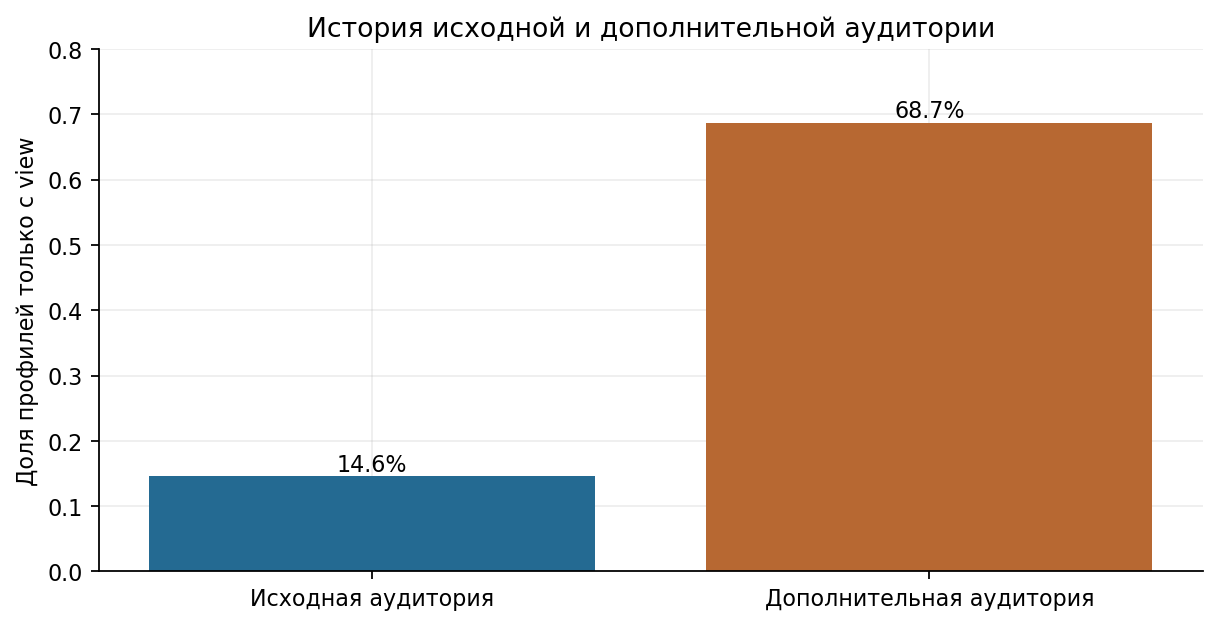

,cohort,pairs,view_only_profile_fraction,fewer_than5_distinct_history_items,median_distinct_history_items,median_history_tokens
0,old,360029,0.146294,0.026359,46.0,55.0
1,additional,414745,0.687442,0.116110,19.0,22.0


In [7]:
profile = read('large_mixed_20261105__training_profile_quality.csv')
fig, ax = plt.subplots(figsize=(7.5,3.8))
ax.bar(['Исходная аудитория','Дополнительная аудитория'],profile.view_only_profile_fraction,color=['#246A92','#B76832'])
ax.set(ylabel='Доля профилей только с view',title='История исходной и дополнительной аудитории',ylim=(0,.8))
for x,v in enumerate(profile.view_only_profile_fraction):ax.text(x,v,f'{v:.1%}',ha='center',va='bottom')
save_figure(fig,figures/'training_population_shift.png')
plt.show()
display(profile)

## Температура

Меняем температуру при одинаковых данных и бюджете. Результаты разделены по seed и периоду оценки.

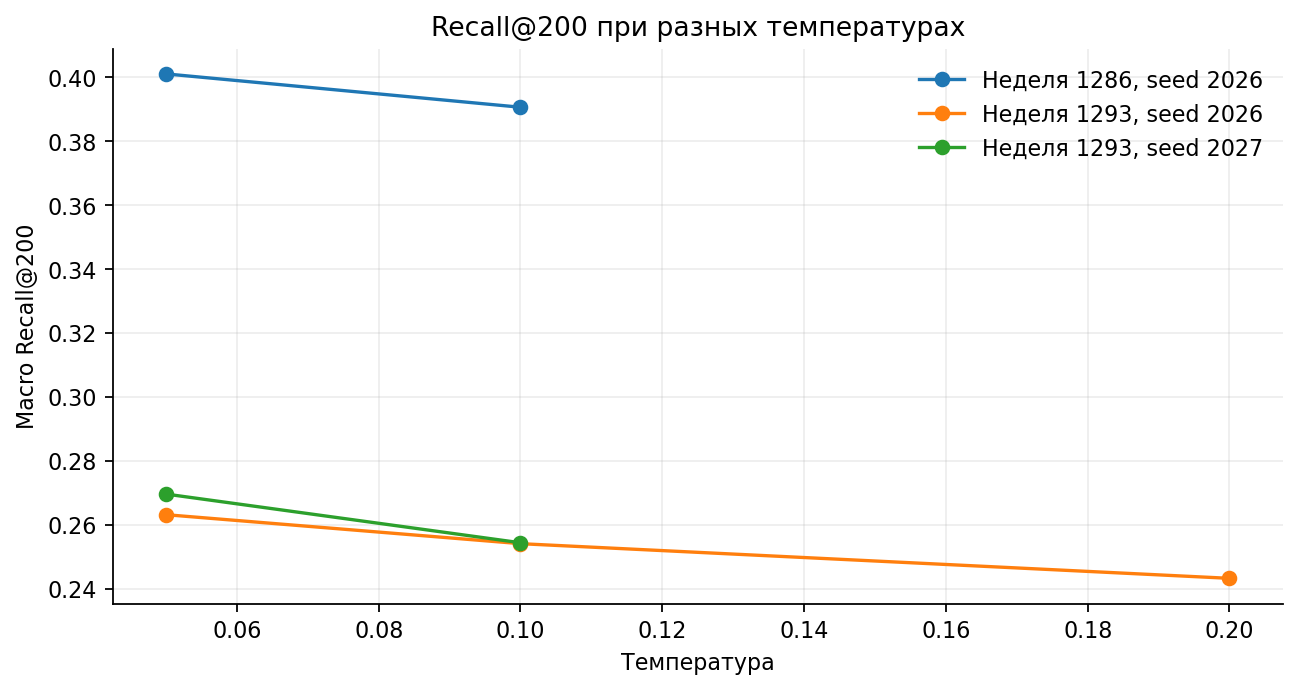

,anchor,seed,temperature,scoring,recall,history_gap,best_updates
0,1293,2026,0.10,raw,0.254034,0.014736,1000
1,1293,2026,0.10,same_fixed_prior,0.288211,0.011153,1000
2,1293,2026,0.05,raw,0.263097,0.005892,500
3,1293,2026,0.05,same_fixed_prior,0.261144,0.003100,500
4,1293,2026,0.20,raw,0.243191,0.001575,500
5,1293,2026,0.20,same_fixed_prior,0.261169,0.003303,500
6,1293,2027,0.10,raw,0.254320,0.004465,500
7,1293,2027,0.10,same_fixed_prior,0.259705,0.003127,500
8,1293,2027,0.05,raw,0.269547,0.016425,1500
9,1293,2027,0.05,same_fixed_prior,0.277892,0.008788,1500


In [8]:
temperatures = read('focused_hypotheses_20261107__temperature_summary.csv')
raw = temperatures[temperatures.scoring == 'raw']
fig, ax = plt.subplots(figsize=(8,4.2))
for (anchor,seed),d in raw.groupby(['anchor','seed']):
    d=d.sort_values('temperature')
    ax.plot(d.temperature,d.recall,'o-',label=f'Неделя {anchor}, seed {seed}')
ax.set(xlabel='Температура',ylabel='Macro Recall@200',title='Recall@200 при разных температурах')
ax.legend(frameon=False)
save_figure(fig, figures / 'temperature.png')
plt.show()
display(temperatures[['anchor','seed','temperature','scoring','recall','history_gap','best_updates']])

## Скорость обучения и градиенты

Сравниваем длительные запуски со стандартным и блочным расчётом. [Проверка градиентов](../appendix_mps/README.md)

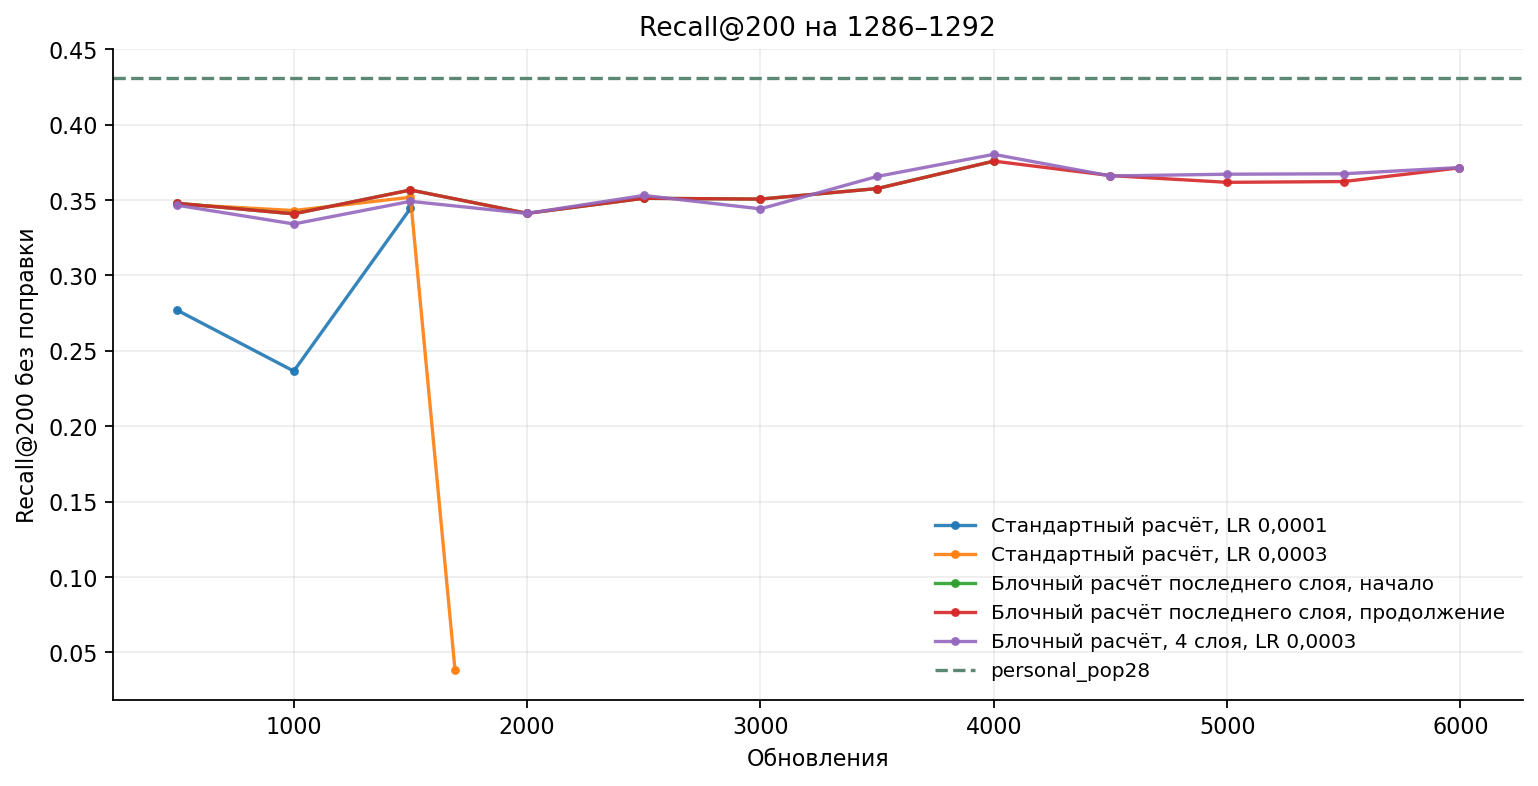

In [9]:
curves = read('stability_lr_20261108__all_learning_curves.csv')
fig, ax = plt.subplots(figsize=(9.5,4.8))
for run,d in curves.groupby('run'):
    label = ('Блочный расчёт, 4 слоя, LR 0,0003' if 'tiledall' in run else
             ('Блочный расчёт последнего слоя, продолжение' if 'resume' in run else 'Блочный расчёт последнего слоя, начало') if 'tiled' in run else
             'Стандартный расчёт, LR 0,0001' if '0p0001' in run else 'Стандартный расчёт, LR 0,0003')
    ax.plot(d.updates,d.recall,marker='.',label=label,alpha=.9)
ax.axhline(.4307606552310291,color='#5C8873',ls='--',label='personal_pop28')
ax.set(xlabel='Обновления',ylabel='Recall@200 без поправки',title='Recall@200 на 1286–1292')
ax.legend(frameon=False,fontsize=9)
save_figure(fig, figures / 'stability_curves.png')
plt.show()

In [10]:
stability = read('stability_lr_20261108__comparison.csv')
stable = stability[stability.run.str.contains('tiledall')]
display(stable[['run','score','recall_reachable@200','own_minus_shuffled','best_updates','completed_updates','fraction_of_one_pass']])
assert np.isclose(stable.loc[stable.score == 'raw','recall_reachable@200'].iloc[0],.3803030732046806)

,run,score,recall_reachable@200,own_minus_shuffled,best_updates,completed_updates,fraction_of_one_pass
6,strong_all_seed2026_lr0p0003_8epochs_tiledall1...,raw,0.380303,0.015884,4000.0,5992.0,8.0
7,strong_all_seed2026_lr0p0003_8epochs_tiledall1...,same_fixed_prior,0.397490,0.010895,4000.0,5992.0,8.0
8,strong_all_seed2026_lr0p0003_8epochs_tiledall1...,raw_fusion10_exploratory,0.430649,NaN,NaN,NaN,NaN


## Функция потерь и качество на валидации

Сравниваем стандартный и блочный расчёт градиентов при одинаковом learning rate. Качество оцениваем по validation Recall@200.

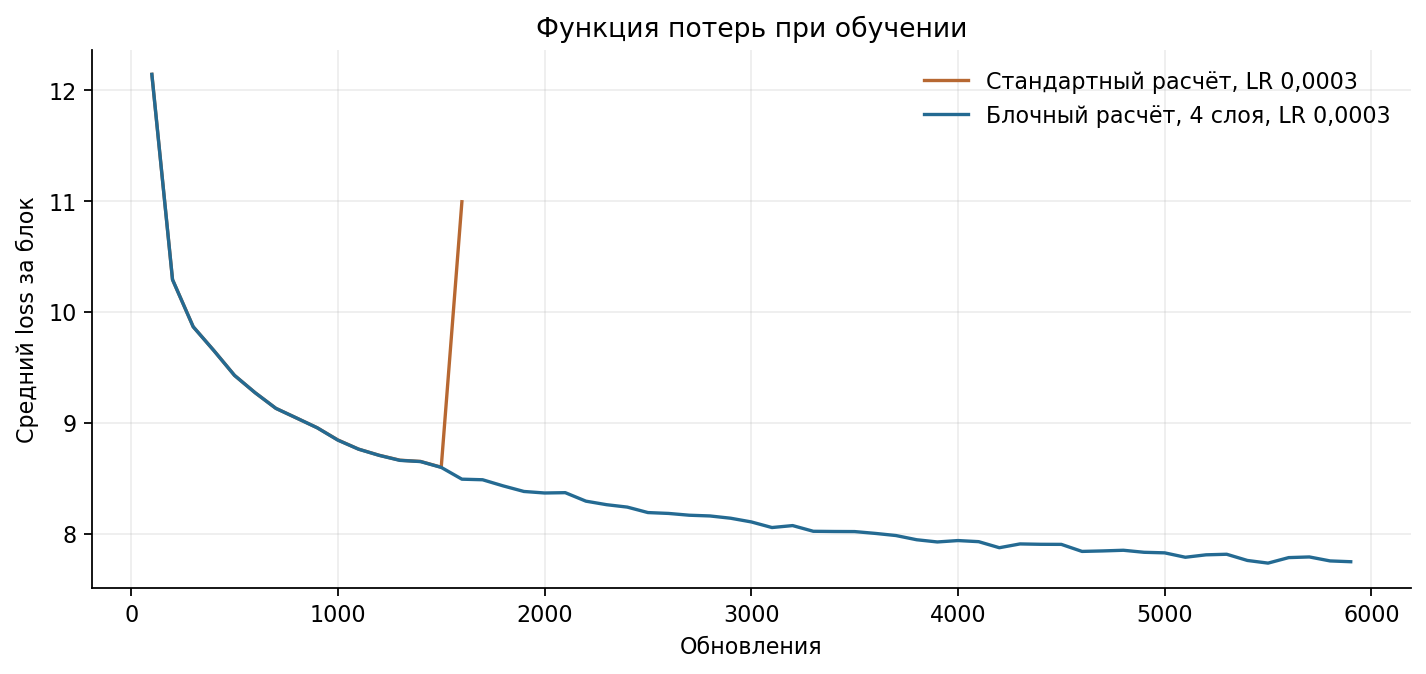

In [11]:
fig, ax = plt.subplots(figsize=(8.8,4.1))
for run,label,color in [
    ('strong_all_seed2026_lr0p0003_8epochs_monitored','Стандартный расчёт, LR 0,0003','#B76832'),
    ('strong_all_seed2026_lr0p0003_8epochs_tiledall16384','Блочный расчёт, 4 слоя, LR 0,0003','#246A92')]:
    loss = read('stability_lr_20261108__' + run + '__training_loss.csv')
    ax.plot(loss.updates,loss.mean_loss,label=label,color=color)
ax.set(xlabel='Обновления',ylabel='Средний loss за блок',title='Функция потерь при обучении')
ax.legend(frameon=False)
save_figure(fig,figures/'training_loss.png')
plt.show()

Совпадение шага Adam с эталоном проверяет обновление по данному градиенту. Правильность самого градиента проверяется отдельно на одинаковом входе CPU и MPS.

## Cosine Contrastive Loss

Порог 0,5 проверили до шага 2000. Обучение с порогом 0,8 остановили на шаге 1500. Вес негативов в обоих опытах равен 50.

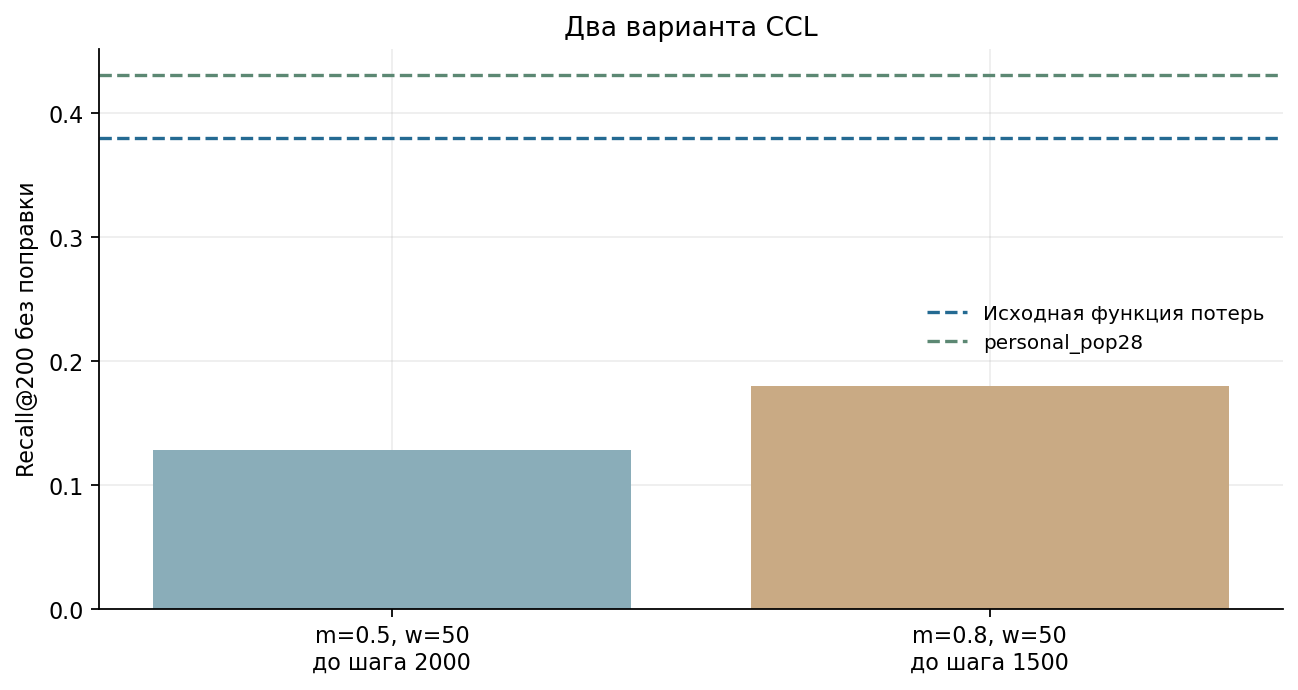

,Порог,Вес негативов,Лучший Recall@200,Лучший шаг,Шаг остановки
0,0.5,50.0,0.127965,1000,2000
1,0.8,50.0,0.180002,1000,1500


In [12]:
ccl = read('ccl_20261108__stopped_study_summary.csv')
observed = ccl.loc[ccl.best_recall.notna()].copy()
labels = [f'm={row.margin:g}, w={row.negative_weight:g}\nдо шага {int(row.durable_update)}'
          for row in observed.itertuples()]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(labels, observed.best_recall, color=['#8AADB9', '#C9AA84'])
ax.axhline(.3803030732046806, color='#246A92', ls='--', label='Исходная функция потерь')
ax.axhline(.4307606552310291, color='#5C8873', ls='--', label='personal_pop28')
ax.set(ylabel='Recall@200 без поправки', title='Два варианта CCL')
ax.legend(frameon=False, fontsize=9)
save_figure(fig, figures / 'ccl_status.png')
plt.show()

table = observed[['margin', 'negative_weight', 'best_recall', 'best_update', 'durable_update']].copy()
table[['best_update', 'durable_update']] = table[['best_update', 'durable_update']].astype(int)
display(table.rename(columns={
    'margin': 'Порог', 'negative_weight': 'Вес негативов', 'best_recall': 'Лучший Recall@200',
    'best_update': 'Лучший шаг', 'durable_update': 'Шаг остановки',
}))

## Вывод

Восьмипроходный запуск с блочным расчётом градиентов показал пользу личной истории, но уступил personal_pop28. Новый запуск и объединение с ALS представлены в главе 07.